# Análise Exploratória de Dados (EDA) - Modelo Preditivo Klike

# 1. Carregamento dos dados


In [118]:
# Instalação caso necessário no ambiente:
# !pip install pandas numpy matplotlib seaborn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configurações estéticas e de exibição
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda x: '%.4f' % x)

# Carregamento da base de dados
caminho_csv = 'base_de_dados/klike_challenge_dataset.csv'
df = pd.read_csv(caminho_csv)

print(f"Dimensões do Dataset: {df.shape[0]} amostras (linhas) e {df.shape[1]} atributos (colunas).")
df.head()

Dimensões do Dataset: 500 amostras (linhas) e 26 atributos (colunas).


,campaign_id,date,platform,category,objective,target_audience_age,is_retargeting,video_duration_s,format,has_subtitle,has_cta,has_hook,has_face,text_density,music_voice_ratio,impressions,clicks,ctr,cpc,spend,conversions,revenue,roas,avg_watch_time_s,engagement_rate,klike_score
0,KLK-0001,2024-01-01,Meta,Branding,awareness,18-24,False,NaN,vertical,True,True,False,True,medium,0.3900,150825,5882,0.0390,0.8200,4823.2400,48,0.0000,0.0000,3.9000,0.0446,63.6000
1,KLK-0002,2024-03-22,LinkedIn,App Install,traffic,25-34,False,NaN,horizontal,True,True,True,True,low,0.0700,7433,493,0.0664,3.5400,1745.2200,34,NaN,0.1600,6.4000,0.0217,70.0000
2,KLK-0003,2024-05-04,TikTok,SaaS,traffic,25-34,False,8.0000,vertical,True,True,True,True,medium,0.4300,193198,15069,0.0780,0.3800,5726.2200,492,51053.4400,8.9200,8.0000,0.1000,99.1000
3,KLK-0004,2024-12-27,TikTok,Lead Gen,engagement,25-34,False,27.0000,quadrado,False,True,True,True,medium,0.5400,6506,601,0.0925,0.7100,426.7100,19,1113.7800,2.6100,20.3000,0.0414,74.9000
4,KLK-0005,2024-07-10,Meta,Branding,engagement,25-34,False,34.0000,vertical,True,True,True,True,low,0.3500,63830,2355,0.0369,0.3800,894.9000,13,0.0000,0.0000,34.0000,0.0184,77.9000


--- 
## 2. Estatísticas Descritivas Iniciais das features

### 2.1 Describe das Variáveis Numéricas

In [119]:
df.describe()

,video_duration_s,music_voice_ratio,impressions,clicks,ctr,cpc,spend,conversions,revenue,roas,avg_watch_time_s,engagement_rate,klike_score
count,461.0000,462.0000,500.0000,500.0000,500.0000,472.0000,500.0000,500.0000,475.0000,500.0000,473.0000,468.0000,500.0000
mean,19.3926,0.3998,153738.5240,3594.1040,0.0710,1.1129,4213.1516,131.3520,6367.9369,2.4990,10.6643,0.0280,60.1568
std,13.5294,0.2027,1171735.6124,7018.2125,0.0453,1.9556,11573.9756,314.5654,19267.1807,3.5924,10.5333,0.0231,15.5891
min,5.0000,0.0200,1000.0000,4.0000,0.0022,0.0500,2.9600,0.0000,0.0000,0.0000,0.4000,0.0010,10.4000
25%,11.0000,0.2300,9986.0000,461.7500,0.0332,0.5300,313.4525,10.0000,262.1750,0.4300,4.7000,0.0111,49.7750
50%,16.0000,0.3850,23241.0000,1351.0000,0.0628,0.7100,1031.0000,34.5000,1201.0500,1.4900,7.7000,0.0214,60.5500
75%,25.0000,0.5500,55172.7500,3583.2500,0.1048,1.0200,2867.9525,111.0000,4189.0250,3.2500,13.9000,0.0388,71.9250
max,115.0000,0.9200,14052761.0000,72545.0000,0.1500,26.0500,121226.1000,3666.0000,241597.2900,39.9200,108.0000,0.1000,99.1000


### 2.2 Describe das Variáveis Categóricas e Booleanas


In [120]:
df.describe(include=['object', 'bool', 'str'])

,campaign_id,date,platform,category,objective,target_audience_age,is_retargeting,format,has_subtitle,has_cta,has_hook,has_face,text_density
count,500,500,500,500,500,500,500,500,454,500,500,500,500
unique,500,273,3,5,5,4,2,3,2,2,2,2,3
top,KLK-0001,2024-06-27,Meta,E-commerce,conversions,25-34,False,vertical,True,True,True,True,medium
freq,1,6,241,165,165,143,383,269,263,347,256,269,230


--- 
## 3. Dicionário de Dados e Características de Cada Variável

Para planejar o pipeline de modelagem, é fundamental classificar cada variável em sua taxonomia estatística e entender seu papel no domínio do problema:

| Tipo de Variável | Nome da Feature | Descrição e Papel de Negócio | Ação Recomendada na Modelagem |
| :--- | :--- | :--- | :--- |
| **Identificador (ID)** | `campaign_id` | Identificador único de cada campanha (ex: `KLK-0001`). Não possui poder preditivo intrínseco. | Descartaremos pois não oferece nenhum benefício e é apenas uma variavel de identificação |
| **Temporal (Datetime)** | `date` | Data de publicação da campanha (`YYYY-MM-DD`). | Converter para `datetime`. Permite extrair features de tempo (dia da semana, mês) e estruturar split temporal (treino no passado, teste no futuro). |
| **Categórica Nominal** | `platform` | Plataforma de veiculação (`Meta`, `LinkedIn`, `TikTok`). Não há relação de ordem entre plataformas. | Aplicar **One-Hot Encoding** (ou Target Encoding). |
| **Categórica Nominal** | `category` | Vertical ou segmento de mercado do anúncio (`Branding`, `App Install`, `E-commerce`, `Lead Gen`, `SaaS`). | Aplicar **One-Hot Encoding**. |
| **Categórica Nominal** | `objective` | Meta declarada no gerenciador de anúncios (`awareness`, `traffic`, `conversions`, `engagement`, `app_install`). | Aplicar **One-Hot Encoding**. |
| **Categórica Nominal** | `format` | Orientação de tela do vídeo (`horizontal`, `quadrado`, `vertical`). | Aplicar **One-Hot Encoding**. |
| **Categórica Ordinal** | `target_audience_age` | Faixa etária do público-alvo (`18-24`, `25-34`, `35-44`, `45+`). Existe uma ordem biológica/etária clara. | Aplicar **Ordinal Encoding** respeitando a ordem natural (ex: 0, 1, 2, 3). |
| **Categórica Ordinal** | `text_density` | Volume de texto sobreposto no vídeo (`low`, `medium`, `high`). Existe uma escala de intensidade. | Aplicar **Ordinal Encoding** (`low: 0, medium: 1, high: 2`). |
| **Binária / Booleana** | `is_retargeting` | Flag indicando se o anúncio é de remarketing (`True`/`False`). | Mapear para binário (`0` e `1`). |
| **Binária / Booleana** | `has_subtitle` | Flag indicando presença de legenda no vídeo (`True`/`False`). Possui valores ausentes. | Tratar nulos e mapear para binário (`0` e `1`). |
| **Binária / Booleana** | `has_cta` | Flag indicando presença de Call to Action (`True`/`False`). | Mapear para binário (`0` e `1`). |
| **Binária / Booleana** | `has_hook` | Flag indicando se há gancho forte nos primeiros segundos (`True`/`False`). | Mapear para binário (`0` e `1`). |
| **Binária / Booleana** | `has_face` | Flag indicando se rostos humanos aparecem no vídeo (`True`/`False`). | Mapear para binário (`0` e `1`). |
| **Numérica Contínua** | `video_duration_s` | Duração do criativo em segundos. | Tratar nulos e avaliar normalização. |
| **Numérica Contínua** | `music_voice_ratio` | Razão acústica entre trilha sonora musical e fala humana (0.0 a 1.0). | Tratar nulos e escala. |
| **Numérica Discreta** | `impressions` | Volume absoluto de exibições do anúncio. Escala muito ampla (milhares a centenas de milhares). | Transformação Logarítmica (`log1p`) e padronização. |
| **Numérica Discreta** | `clicks` | Número absoluto de cliques obtidos. | Transformação Logarítmica (`log1p`) devido à alta assimetria. |
| **Numérica Contínua** | `ctr` | Taxa de cliques ($clicks / impressions$). Métrica percentual relativa (0.0 a 1.0). | Escalonamento MinMax ou Standard. |
| **Numérica Contínua** | `cpc` | Custo médio por clique ($spend / clicks$). Possui nulos. | Tratar nulos via regra ($spend / clicks$) ou mediana; tratar outliers. |
| **Numérica Contínua** | `spend` | Investimento financeiro total na campanha ($). | Transformação Logarítmica (`log1p`) ou RobustScaler. |
| **Numérica Discreta** | `conversions` | Número de conversões geradas pela campanha. | Transformação Logarítmica devido a zeros e valores extremos. |
| **Numérica Contínua** | `revenue` | Faturamento gerado pela campanha. Possui nulos. | Tratar nulos; transformação Logarítmica. |
| **Numérica Contínua** | `roas` | Retorno sobre o gasto em anúncios ($revenue / spend$). | Avaliar outliers extremos e robustez. |
| **Numérica Contínua** | `avg_watch_time_s` | Tempo médio de retenção do usuário assistindo ao vídeo. Possui nulos. | Tratar nulos (mediana) e escalonamento. |
| **Numérica Contínua** | `engagement_rate` | Proporção de interações pelo total de alcance. Possui nulos. | Tratar nulos e escalonar. |
| **Variável Alvo (Target)**| `klike_score` | Métrica contínua (0 a 100) que quantifica a eficácia global do criativo. | **Variável Dependente ($y$)**. Verificar se a distribuição é normal para escolher a função de perda (MSE, MAE, Huber). |

--- 
## 4. Diagnóstico e Identificação de Valores Ausentes (Missing Values)

Aqui vamos entender quais são as features que contém valores ausentes, para que assim, possamos identificar a melhor estratégia para subistítui-los

In [121]:
# Cálculo de contagem absoluta e percentual de valores faltantes
nulos = df.isnull().sum()
pct_nulos = (nulos / len(df)) * 100

tabela_nulos = pd.DataFrame({
    'Tipo de Dado': df.dtypes,
    'Valores Ausentes': nulos,
    'Percentual (%)': pct_nulos
})

# Filtrando apenas as colunas que possuem ao menos 1 valor ausente
tabela_nulos_filtrada = tabela_nulos[tabela_nulos['Valores Ausentes'] > 0].sort_values(by='Valores Ausentes', ascending=False)
tabela_nulos_filtrada

,Tipo de Dado,Valores Ausentes,Percentual (%)
has_subtitle,object,46,9.2000
video_duration_s,float64,39,7.8000
music_voice_ratio,float64,38,7.6000
engagement_rate,float64,32,6.4000
cpc,float64,28,5.6000
avg_watch_time_s,float64,27,5.4000
revenue,float64,25,5.0000


## 4.1 Análise das features com valores ausentes e estratégias de tratamento

| Variável | Porcentagem de nulos | Possível razão | Como substituir os nulos |
|---|---:|---|---|
| `has_subtitle` | ~9,2% | Vídeo sem fala/legenda ou falha de preenchimento. | Preencher com a moda (`True` ou `False`). |
| `video_duration_s` | ~7,8% | Falha na coleta ou indisponibilidade dos metadados de duração. | Preencher com a mediana por categoria/formato de vídeo. |
| `music_voice_ratio` | ~7,6% | Ausência de música ou voz, ou falha na análise do áudio. | Preencher com a mediana geral. |
| `cpc` | ~5,6% | Falha no cálculo ou no preenchimento. | Calcular como `spend / clicks` quando `clicks > 0` e `spend` estiver disponível. |
| `revenue` | ~5,0% | Ausência de conversões ou falha no registro da receita. | Preencher com `0.0` quando `conversions == 0`, se essa regra for válida na base. Para conversões positivas, multiplicar `conversions` pela mediana de receita por conversão da categoria. |
| `avg_watch_time_s` | ~5,4% | Falha na coleta ou ausência de visualizações válidas. | Preencher com a mediana, preferencialmente por grupos de duração/formato semelhantes. |
| `engagement_rate` | ~6,4% | Falha na coleta ou denominador da taxa igual a zero. | Preencher com a mediana quando a taxa estiver ausente. |

**Justificativas**

Partindo da hipótese de que os valores ausentes decorrem, em grande parte, de falhas de cálculo ou de preenchimento, adotaremos a imputação pela moda ou pela mediana, conforme o tipo de variável. Essa hipótese se baseia no fato de que, até o momento, não foram identificadas evidências de que a ausência dos dados esteja associada a um fenômeno sistemático, como o viés de sobrevivência (*survivorship bias*). A moda será utilizada para a variável booleana, enquanto a mediana será aplicada às variáveis numéricas por ser menos sensível a valores extremos.

Quando houver informações suficientes para recuperar o valor por meio de uma fórmula, essa abordagem será priorizada. É o caso de `cpc`, que pode ser calculado a partir de `spend` e `clicks`, respeitando as condições indicadas na tabela. Para as demais variáveis, serão utilizadas as estratégias gerais ou por grupo descritas acima.

--- 
## 5. Análise Gráfica de Distribuições e Detecção de Outliers


In [122]:
# Lista de todas as features numéricas + variável target
colunas_numericas = [
    'video_duration_s', 'music_voice_ratio', 'impressions', 'clicks', 
    'ctr', 'cpc', 'spend', 'conversions', 'revenue', 'roas', 
    'avg_watch_time_s', 'engagement_rate', 'klike_score'
]

### 5.1 Gráficos de Distribuição (Histogramas e Curvas de Densidade KDE)

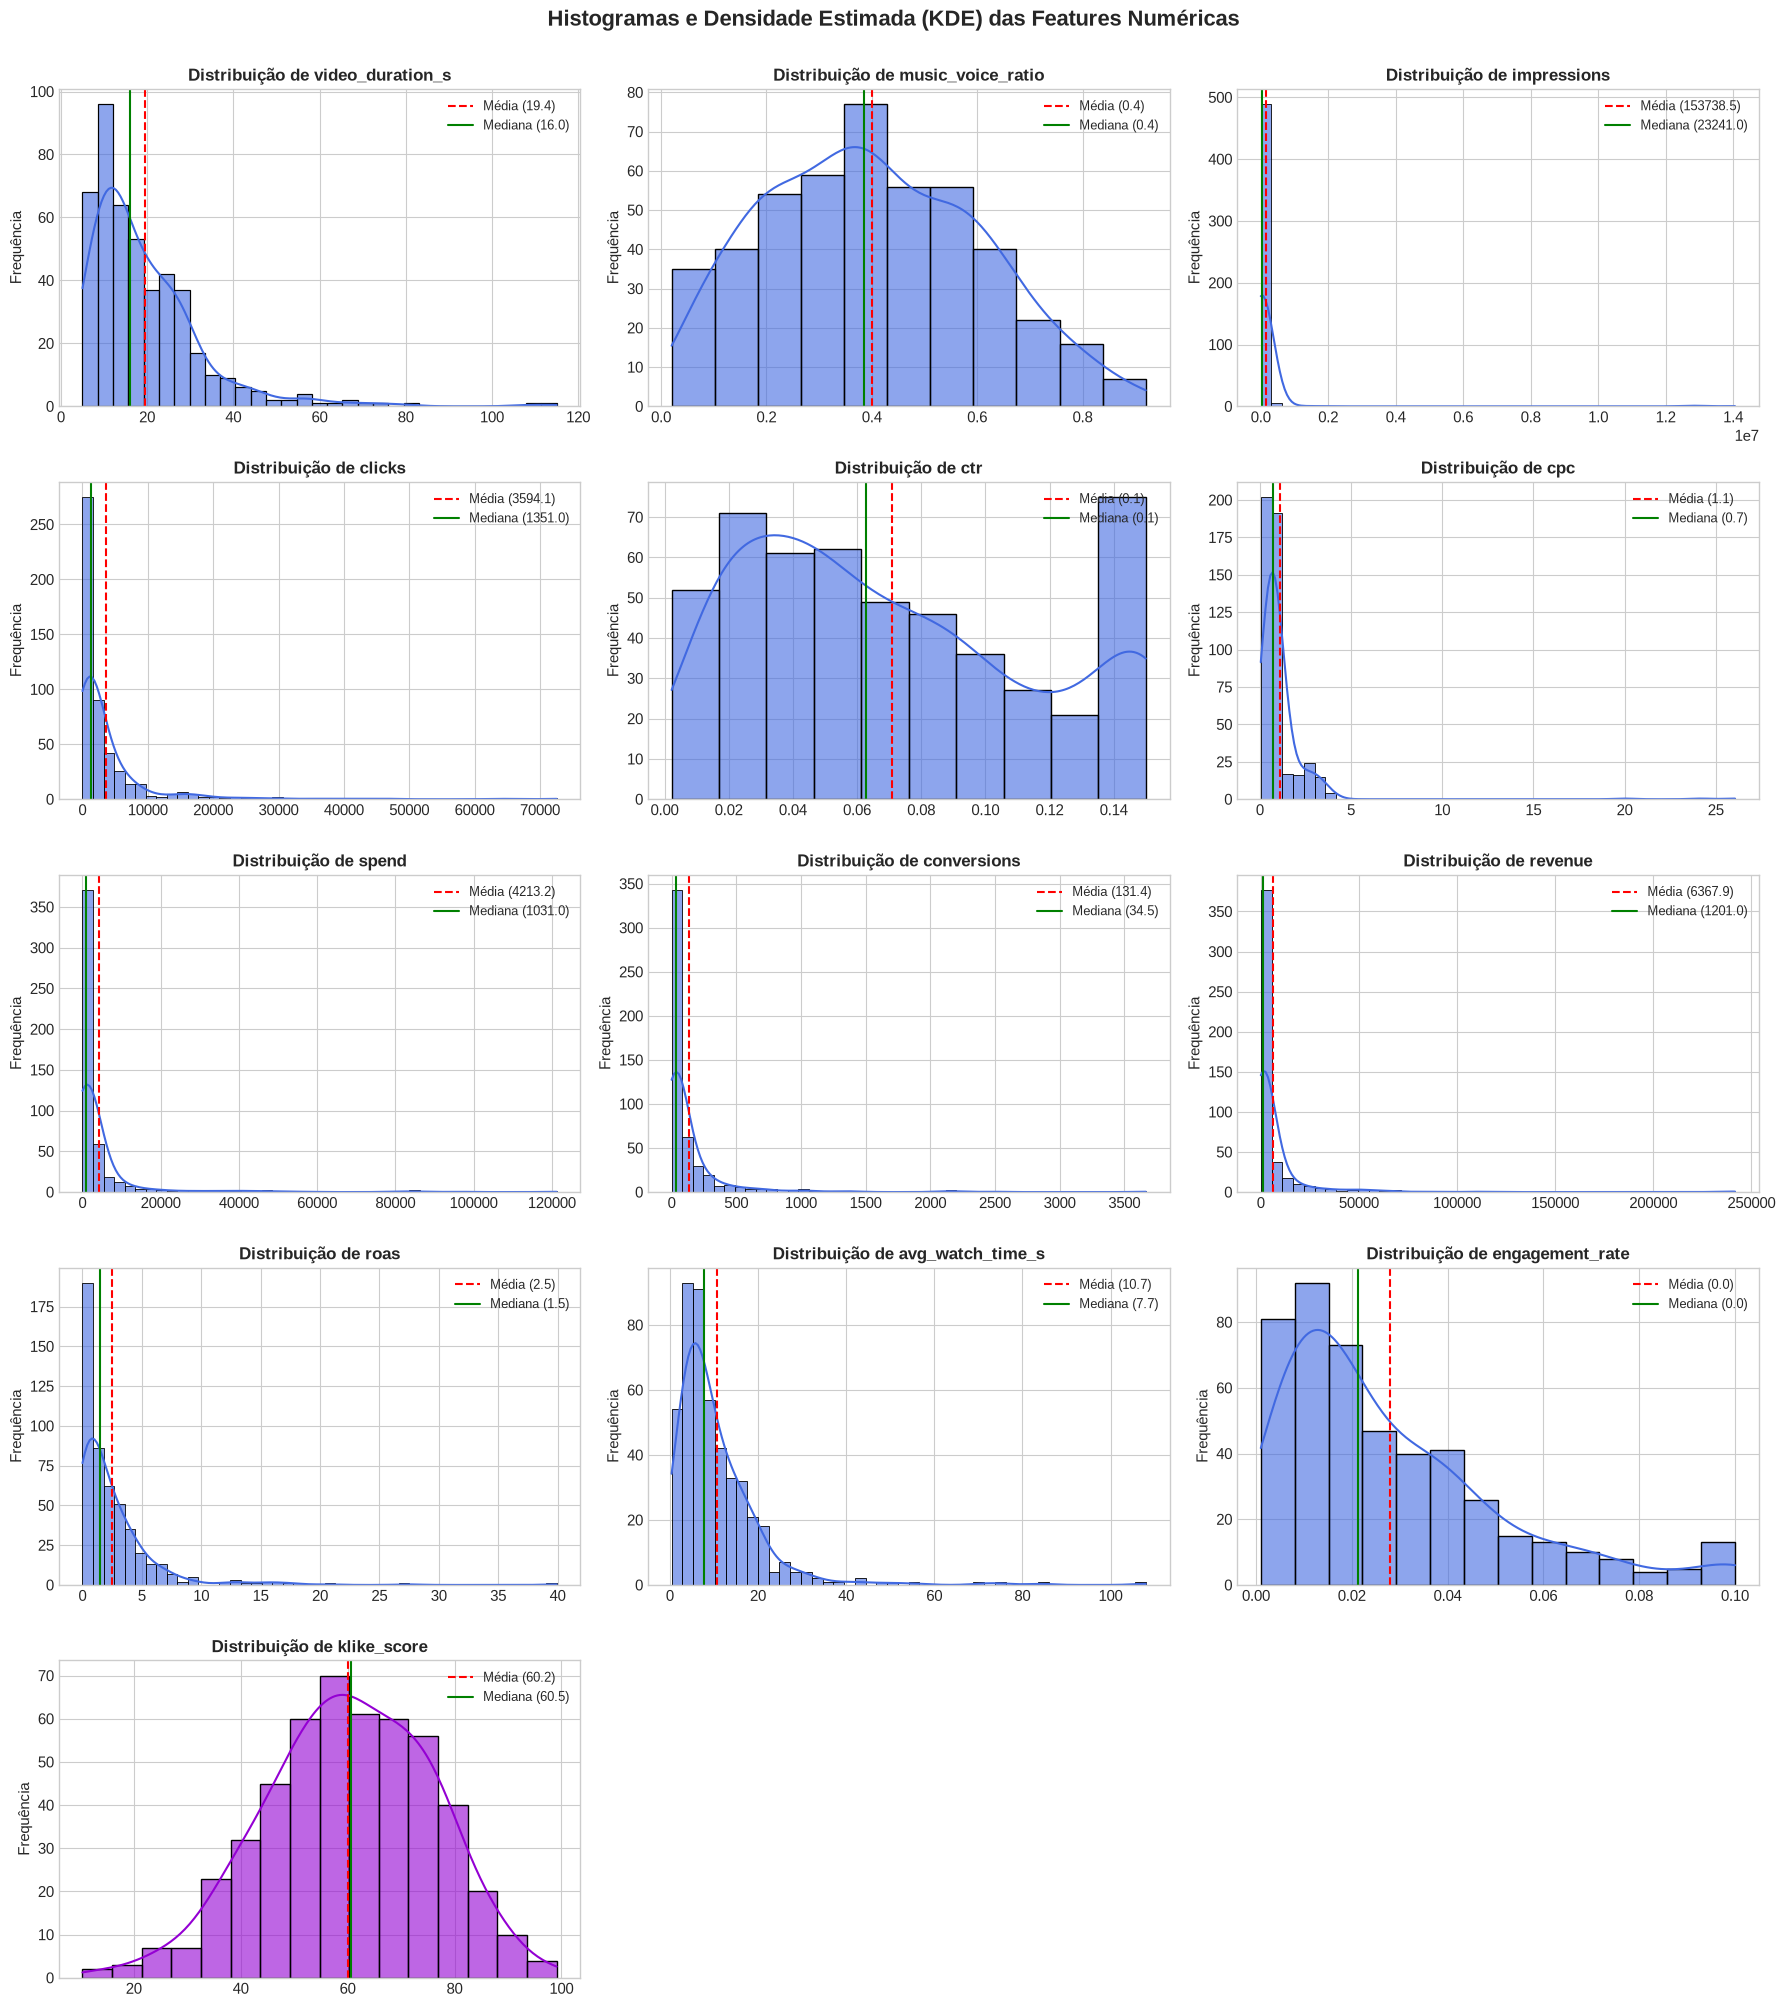

In [123]:
# Plot dos Histogramas e Curvas KDE em grid 5x3
fig, axes = plt.subplots(nrows=5, ncols=3, figsize=(18, 20))
axes = axes.flatten()

for i, col in enumerate(colunas_numericas):
    dados = df[col].dropna()
    cor = 'darkviolet' if col == 'klike_score' else 'royalblue'
    
    sns.histplot(dados, kde=True, ax=axes[i], color=cor, edgecolor='black', alpha=0.6)
    axes[i].set_title(f'Distribuição de {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Frequência')
    
    # Linhas para Média (vermelho) e Mediana (verde)
    media = dados.mean()
    mediana = dados.median()
    axes[i].axvline(media, color='red', linestyle='--', linewidth=1.5, label=f'Média ({media:.1f})')
    axes[i].axvline(mediana, color='green', linestyle='-', linewidth=1.5, label=f'Mediana ({mediana:.1f})')
    axes[i].legend(loc='upper right', fontsize=9)

# Remover eixos vazios restantes
for j in range(len(colunas_numericas), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Histogramas e Densidade Estimada (KDE) das Features Numéricas', fontsize=16, fontweight='bold', y=1.002)
plt.tight_layout()
plt.show()

### 5.2 Gráficos de Boxplot (Detecção de Outliers e Dispersão)

Os pontos individuais desenhados além dos limites dos *whiskers* (bigodes) representam potenciais **outliers** (valores que distam mais de $1.5 \times IQR$ do primeiro ou terceiro quartil).

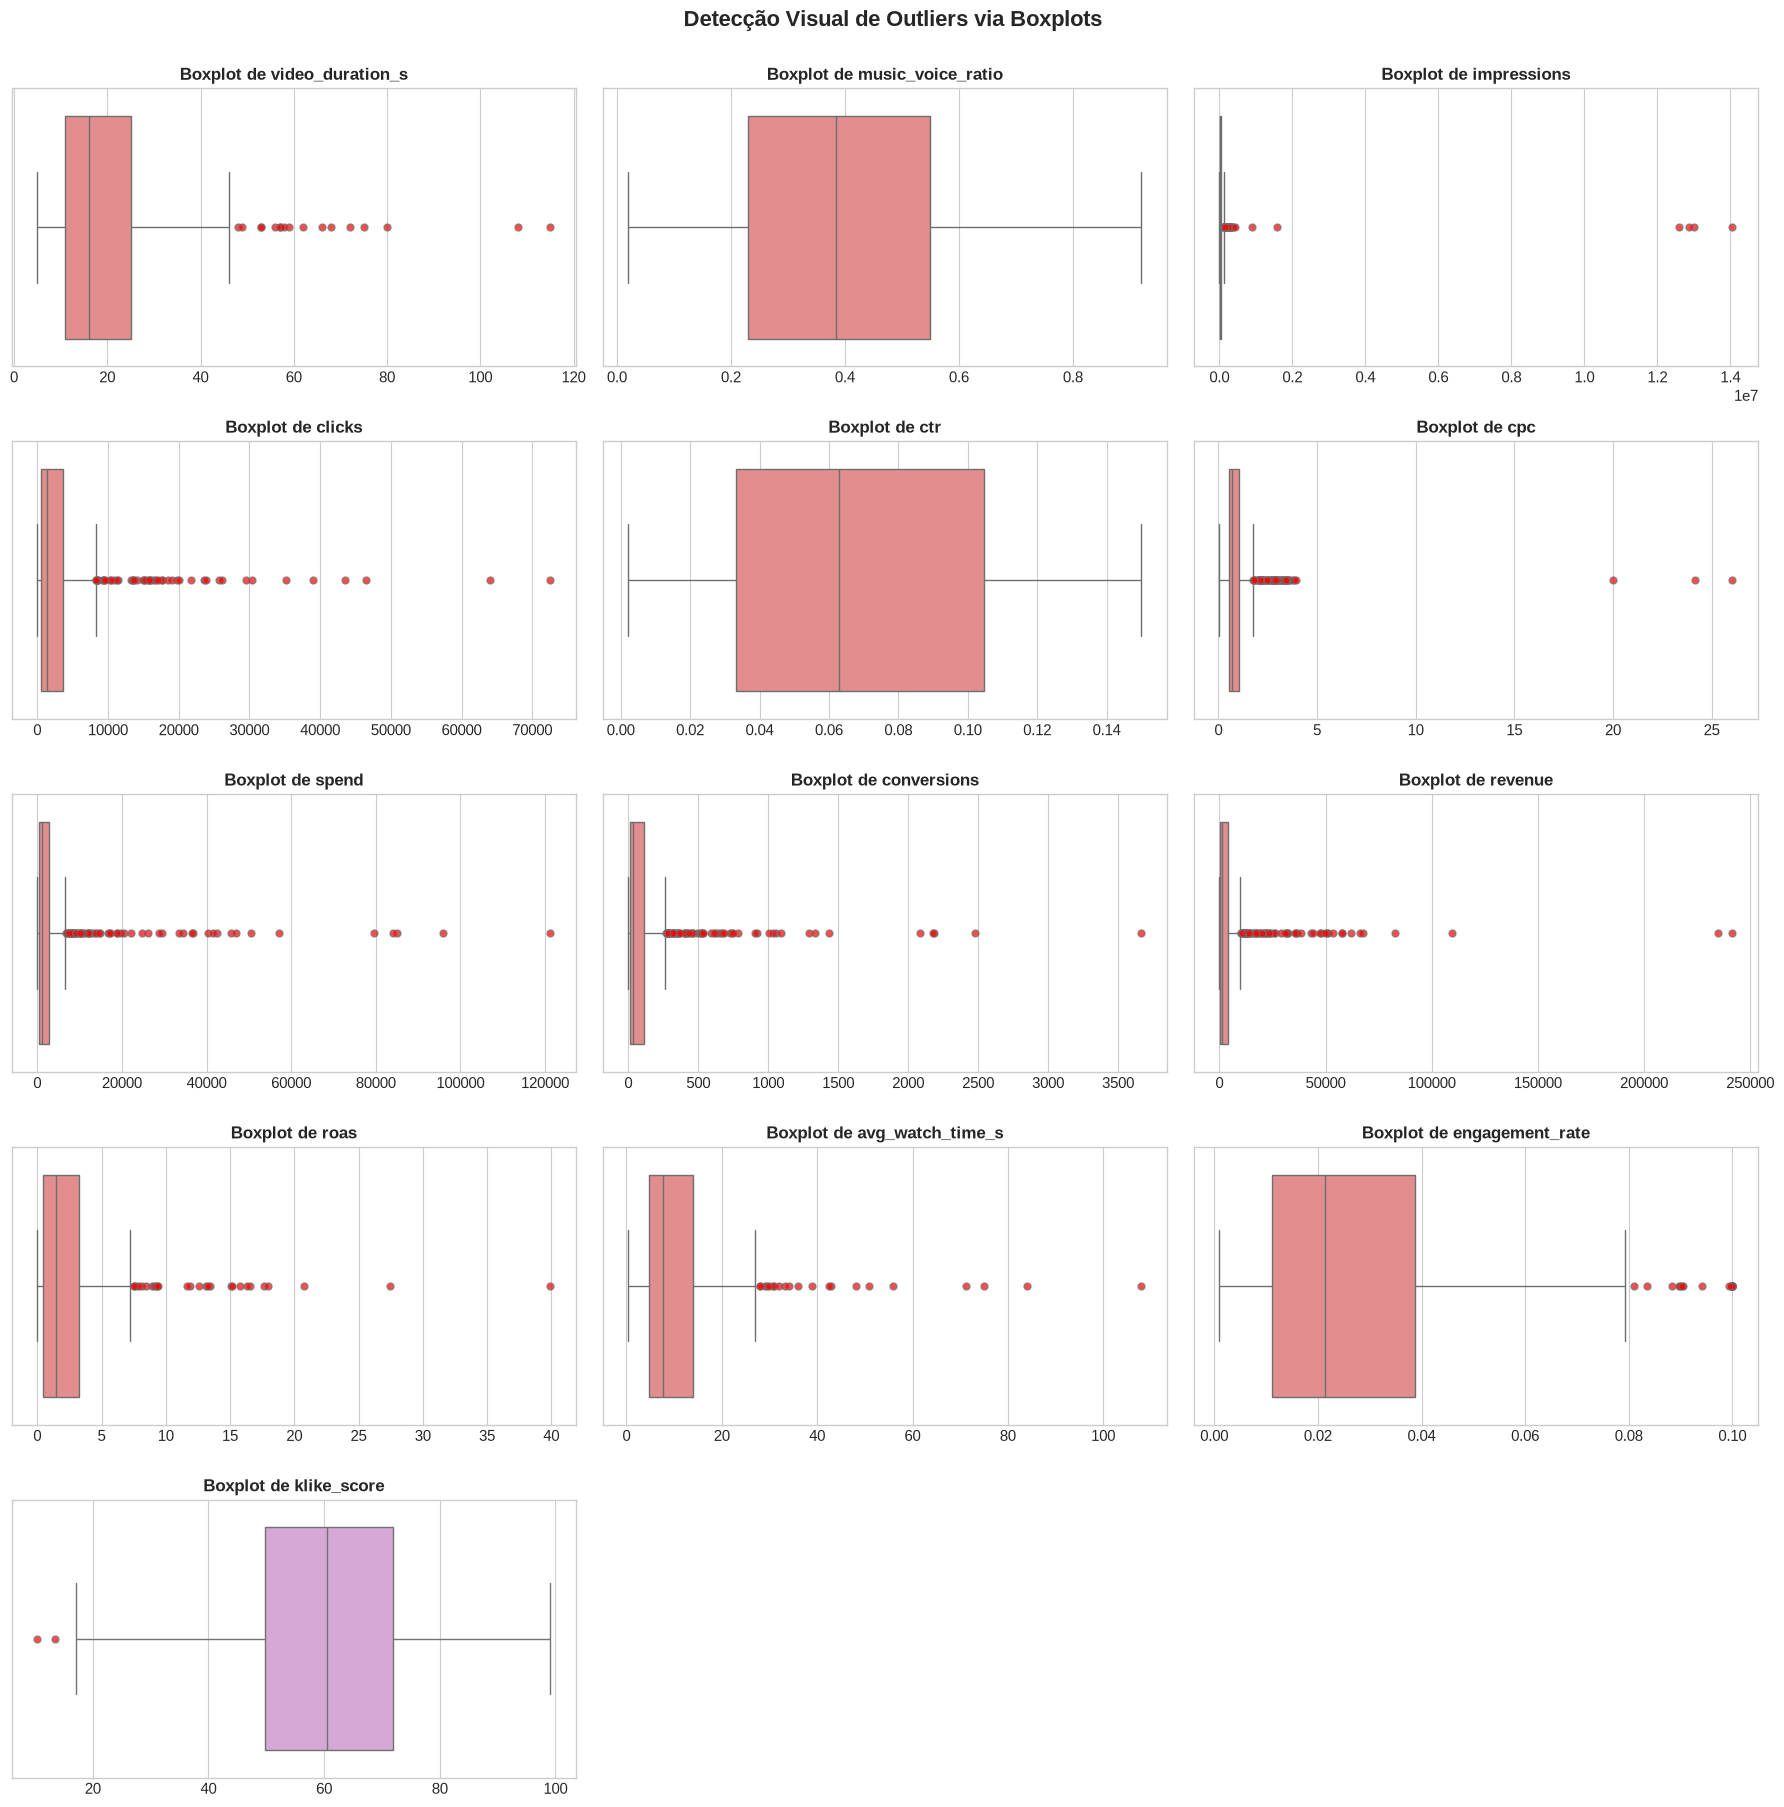

In [124]:
# Plot dos Boxplots em grid 5x3
fig, axes = plt.subplots(nrows=5, ncols=3, figsize=(18, 18))
axes = axes.flatten()

for i, col in enumerate(colunas_numericas):
    cor = 'plum' if col == 'klike_score' else 'lightcoral'
    
    sns.boxplot(
        x=df[col].dropna(), 
        ax=axes[i], 
        color=cor, 
        flierprops={'marker': 'o', 'markersize': 5, 'markerfacecolor': 'red', 'alpha': 0.7}
    )
    axes[i].set_title(f'Boxplot de {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('')

# Remover eixos vazios restantes
for j in range(len(colunas_numericas), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Detecção Visual de Outliers via Boxplots', fontsize=16, fontweight='bold', y=1.002)
plt.tight_layout()
plt.show()

### 5.3 Diagnóstico Numérico de Assimetria (Skewness) e Curtose (Kurtosis)

Para quantificar matematicamente as distorções vislumbradas nos gráficos:
- **Assimetria (Skewness)**:
  - Próximo de $0$: Distribuição simétrica (semelhante à Gaussiana);
  - $> +1.0$: Forte assimetria positiva / cauda longa à direita (concentração de dados nos valores baixos e cauda longa com valores extremos altos);
  - $< -1.0$: Forte assimetria negativa / cauda longa à esquerda.
- **Curtose (Kurtosis)**:
  - Mede a presença de caudas pesadas e pico acentuado em relação à distribuição normal (curtose normal $\approx 0$ no pandas).

In [125]:
# Cálculo de Skewness e Kurtosis para as features numéricas
skew = df[colunas_numericas].skew()
kurt = df[colunas_numericas].kurt()

df_diagnostico = pd.DataFrame({
    'Assimetria (Skewness)': skew,
    'Curtose (Kurtosis)': kurt,
    'Classificação da Assimetria': skew.apply(
        lambda x: 'Forte Assimetria Positiva (Direita)' if x > 1.0
        else ('Assimetria Positiva Moderada' if x > 0.5
        else ('Forte Assimetria Negativa (Esquerda)' if x < -1.0
        else ('Assimetria Negativa Moderada' if x < -0.5
        else 'Aproximadamente Simétrica')))
    ),
    'Recomendação de Pré-Processamento': skew.apply(
        lambda x: 'Transformação Logarítmica (log1p) / Yeo-Johnson'
        if abs(x) > 1.0
        else ('RobustScaler / StandardScaler'
        if abs(x) > 0.5
        else 'StandardScaler / MinMaxScaler')
    )
}).sort_values(by='Assimetria (Skewness)', ascending=False)

df_diagnostico

,Assimetria (Skewness),Curtose (Kurtosis),Classificação da Assimetria,Recomendação de Pré-Processamento
impressions,10.9991,120.4501,Forte Assimetria Positiva (Direita),Transformação Logarítmica (log1p) / Yeo-Johnson
cpc,9.9253,114.2171,Forte Assimetria Positiva (Direita),Transformação Logarítmica (log1p) / Yeo-Johnson
revenue,8.3431,90.2662,Forte Assimetria Positiva (Direita),Transformação Logarítmica (log1p) / Yeo-Johnson
conversions,6.0341,48.2994,Forte Assimetria Positiva (Direita),Transformação Logarítmica (log1p) / Yeo-Johnson
spend,5.9440,42.5994,Forte Assimetria Positiva (Direita),Transformação Logarítmica (log1p) / Yeo-Johnson
clicks,5.1687,36.1735,Forte Assimetria Positiva (Direita),Transformação Logarítmica (log1p) / Yeo-Johnson
roas,4.4036,31.3006,Forte Assimetria Positiva (Direita),Transformação Logarítmica (log1p) / Yeo-Johnson
avg_watch_time_s,4.0143,25.6358,Forte Assimetria Positiva (Direita),Transformação Logarítmica (log1p) / Yeo-Johnson
video_duration_s,2.5553,11.0039,Forte Assimetria Positiva (Direita),Transformação Logarítmica (log1p) / Yeo-Johnson
engagement_rate,1.3073,1.3670,Forte Assimetria Positiva (Direita),Transformação Logarítmica (log1p) / Yeo-Johnson


## Tomada de decisão para a transformação e o escalonamento dos dados

A análise dos histogramas e boxplots revelou que algumas features apresentam forte assimetria à direita e valores extremos. Com base nisso, aplicaremos transformações para reduzir essa assimetria e, quando necessário, escalonaremos as variáveis para colocá-las em escalas comparáveis. Essas escolhas considerarão as características de cada feature e a sensibilidade do modelo à escala e aos valores extremos.

---
## 6. Análise de Correlação e Identificação das Features Mais Importantes

Para compreender o comportamento do target (`klike_score`) e identificar quais variáveis exercem maior influência sobre ele, calculamos dois tipos de correlação:
1. **Correlação Linear de Pearson ($r$)**: mede a relação linear estrita entre pares de variáveis contínuas (sensível a outliers);
2. **Correlação de Postos de Spearman ($\rho$)**: mede a relação **monotônica** (se quando $X$ cresce, $Y$ também tende a crescer, independentemente de ser em linha reta). Por ser baseada em postos/ordenações, é **robusta a outliers e a distribuições com cauda longa**.

In [126]:
# Conversão temporária das variáveis booleanas em flags binárias (0 e 1) para permitir cálculo de correlação
cols_binarias = ['is_retargeting', 'has_subtitle', 'has_cta', 'has_hook', 'has_face']
df_corr = df[colunas_numericas + cols_binarias].copy()

for col in cols_binarias:
    df_corr[col] = df_corr[col].map({True: 1, False: 0})

# Cálculo das correlações com o target klike_score
corr_pearson = df_corr.corr(method='pearson')['klike_score'].drop('klike_score')
corr_spearman = df_corr.corr(method='spearman')['klike_score'].drop('klike_score')

# Montagem do painel comparativo de relevância
tabela_correlacoes = pd.DataFrame({
    'Pearson (Linear)': corr_pearson,
    'Spearman (Monotônica)': corr_spearman,
    'Magnitude / Força': corr_spearman.abs().apply(
        lambda x: 'Muito Forte' if x >= 0.5 
        else ('Forte' if x >= 0.35 
        else ('Moderada' if x >= 0.20 
        else ('Fraca' if x >= 0.08 else 'Desprezível / Nula')))
    ),
    'Sentido do Efeito': corr_spearman.apply(
        lambda x: 'Positivo (Aumenta o Score)' if x > 0.05 
        else ('Negativo (Diminui o Score)' if x < -0.05 else 'Neutro')
    )
}).sort_values(by='Spearman (Monotônica)', ascending=False)

print("=== RANKING DE CORRELAÇÃO DAS FEATURES COM O KLIKE_SCORE ===")
tabela_correlacoes


=== RANKING DE CORRELAÇÃO DAS FEATURES COM O KLIKE_SCORE ===


,Pearson (Linear),Spearman (Monotônica),Magnitude / Força,Sentido do Efeito
has_hook,0.5498,0.5581,Muito Forte,Positivo (Aumenta o Score)
ctr,0.5028,0.5394,Muito Forte,Positivo (Aumenta o Score)
has_face,0.3863,0.3670,Forte,Positivo (Aumenta o Score)
conversions,0.1381,0.3347,Moderada,Positivo (Aumenta o Score)
revenue,0.1371,0.3204,Moderada,Positivo (Aumenta o Score)
clicks,0.1517,0.3032,Moderada,Positivo (Aumenta o Score)
engagement_rate,0.2364,0.2945,Moderada,Positivo (Aumenta o Score)
roas,0.1890,0.2469,Moderada,Positivo (Aumenta o Score)
has_cta,0.2382,0.2376,Moderada,Positivo (Aumenta o Score)
spend,0.0519,0.2366,Moderada,Positivo (Aumenta o Score)


### 6.1 Gráfico de Barras: Ranking das Features com Maior Correlação com o `klike_score`

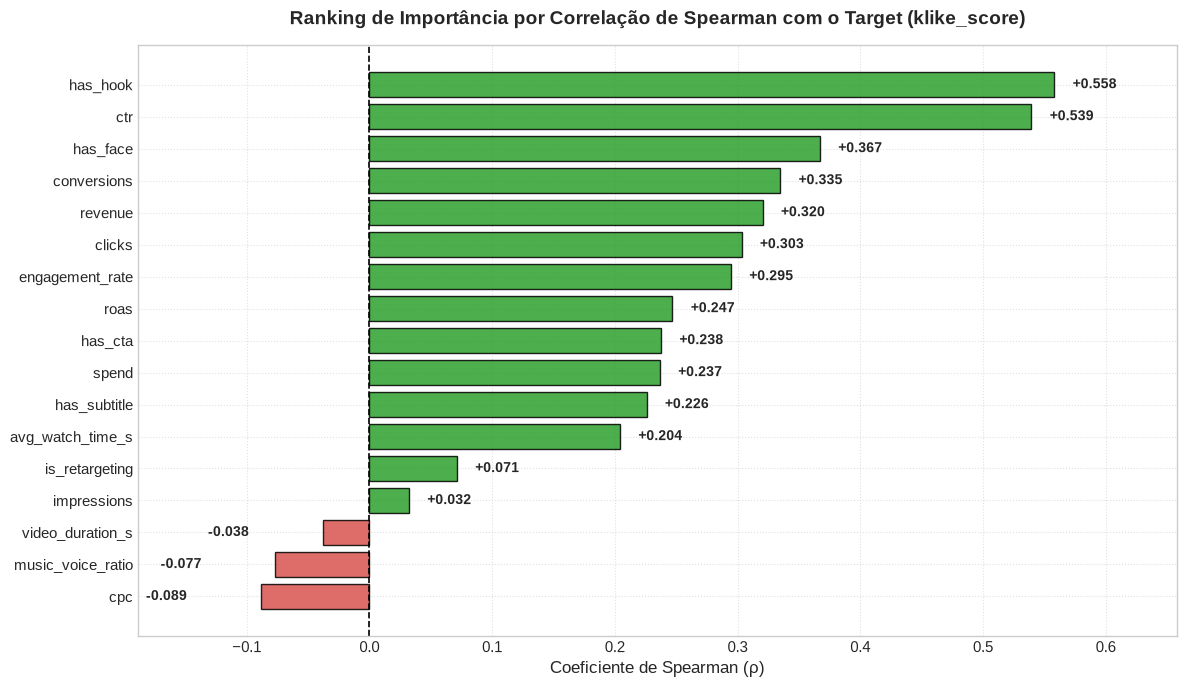

In [127]:
plt.figure(figsize=(12, 7))
dados_plot = tabela_correlacoes['Spearman (Monotônica)'].sort_values()
cores = ['#d9534f' if val < 0 else '#2ca02c' for val in dados_plot]

bars = plt.barh(dados_plot.index, dados_plot.values, color=cores, edgecolor='black', alpha=0.85)
plt.axvline(0, color='black', linewidth=1.2, linestyle='--')
plt.title('Ranking de Importância por Correlação de Spearman com o Target (klike_score)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Coeficiente de Spearman (\u03c1)', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)

# Inserção dos valores em cada barra
for bar in bars:
    w = bar.get_width()
    offset = 0.015 if w >= 0 else -0.06
    plt.text(w + offset, bar.get_y() + bar.get_height()/2, f'{w:+.3f}', 
             va='center', ha='left' if w >= 0 else 'right', fontsize=10, fontweight='bold')

plt.xlim(min(dados_plot.values) - 0.1, max(dados_plot.values) + 0.1)
plt.tight_layout()
plt.show()

### 6.2 Heatmap da Matriz de Correlação Completa (Multicolinearidade)

Além da relação com o target, precisamos verificar se as features preditivas estão **fortemente correlacionadas entre si** (**multicolinearidade**). Variáveis redundantes podem inflacionar a variância dos coeficientes em modelos lineares.

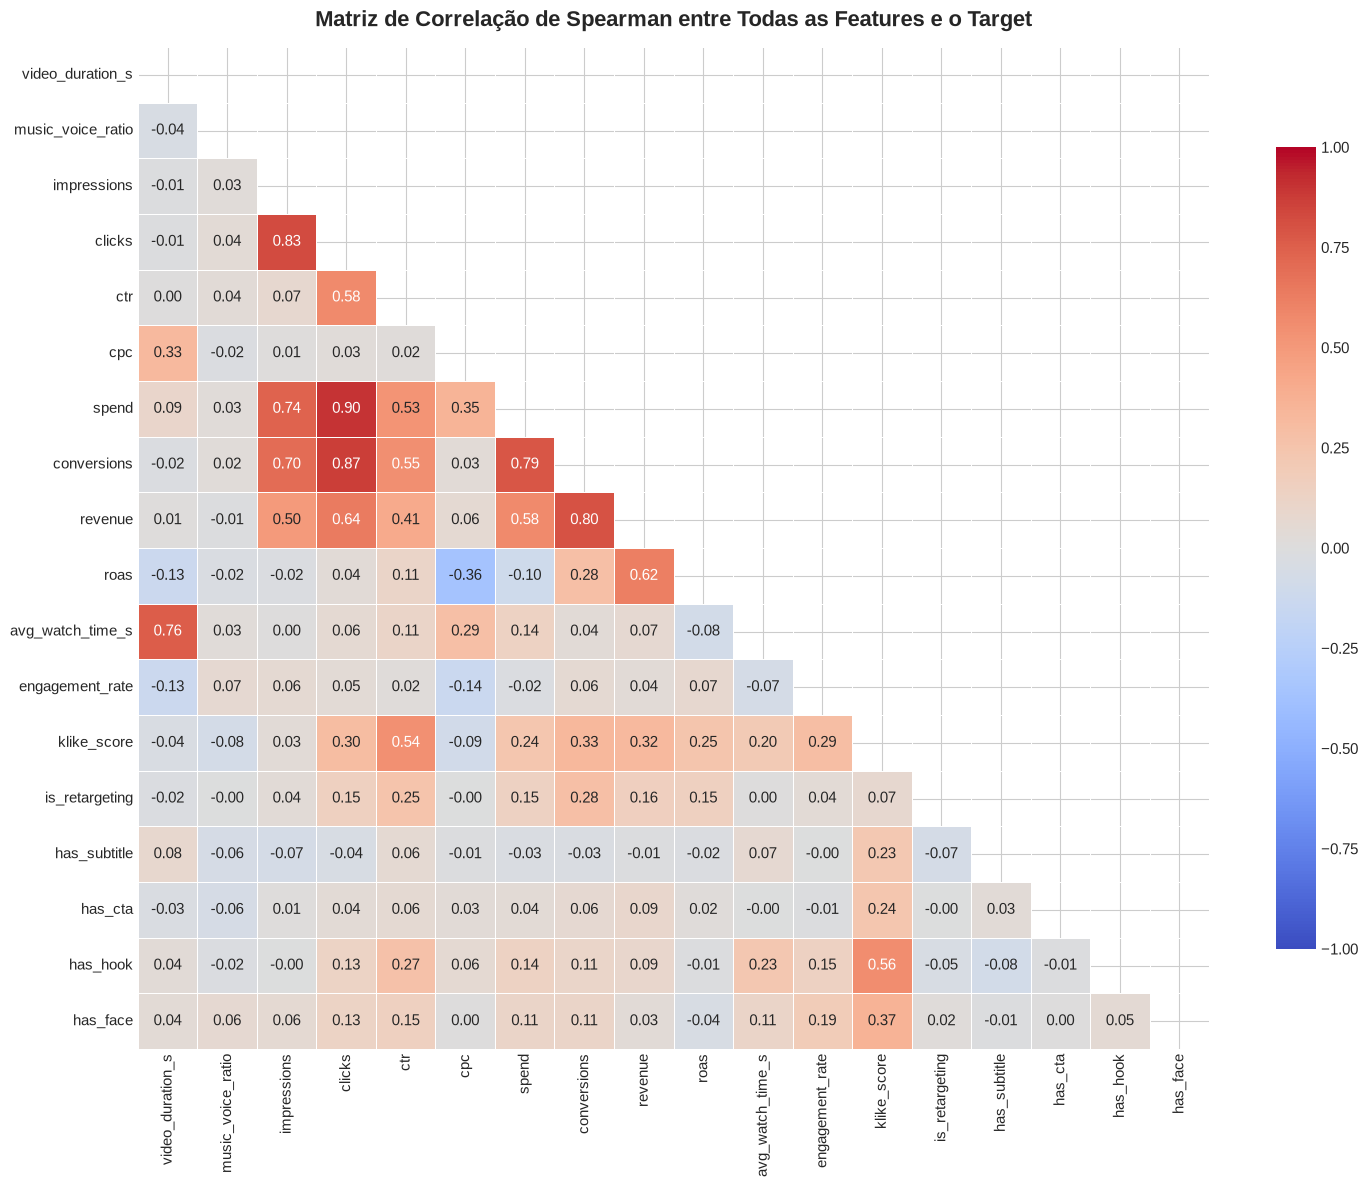

In [128]:
plt.figure(figsize=(15, 12))
matriz_corr = df_corr.corr(method='spearman')

# Máscara triangular superior para evitar redundância visual
mascara = np.triu(np.ones_like(matriz_corr, dtype=bool))

sns.heatmap(
    matriz_corr, 
    mask=mascara, 
    annot=True, 
    fmt='.2f', 
    cmap='coolwarm', 
    vmin=-1, 
    vmax=1, 
    linewidths=0.5, 
    cbar_kws={'shrink': 0.8}
)
plt.title('Matriz de Correlação de Spearman entre Todas as Features e o Target', fontsize=16, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

### 6.3 Principais Descobertas sobre as Features Mais Importantes

1. **Principais Alavancas do Criativo (Conteúdo do Vídeo)**:
   - **`has_hook` (Gancho Inicial) [$\approx +0.55$]**: É a feature qualitativa mais forte de todo o dataset. Anúncios com gancho nos primeiros segundos têm escores dramaticamente superiores.
   - **`has_face` (Presença de Rosto Humano) [$\approx +0.39$]**: Presença de pessoas/rostos humanos gera maior conexão e alavanca o score.
   - **`has_cta` (Call to Action) [$\approx +0.24$]** e **`has_subtitle` (Legenda) [$\approx +0.23$]**: Contribuem positivamente para a retenção e clareza da mensagem.

2. **Principais Métricas de Eficiência e Engajamento**:
   - **`ctr` (Click-Through Rate) [$\approx +0.54$]**: A taxa de clique é a métrica quantitativa mais fortemente associada ao `klike_score`.
   - **`conversions` [$\approx +0.33$]**, **`revenue` [$\approx +0.32$]** e **`clicks` [$\approx +0.30$]**: Em correlação monotônica (Spearman), o volume de conversão e receita mostra sólida relação positiva com o score.
   - **`engagement_rate` [$\approx +0.29$]** e **`roas` [$\approx +0.25$]**: Também apresentam correlações moderadas positivas consistentes.

3. **Features Neutras ou com Correlação Inversa**:
   - **`cpc` [$\approx -0.09$]**: Correlação negativa esperada — campanhas mais eficientes tendem a ter menor custo por clique.
   - **`music_voice_ratio` [$\approx -0.08$]** e **`video_duration_s` [$\approx -0.04$]**: Correlações próximas de zero, sugerindo que o sucesso depende mais de *como* o vídeo é feito (hook, face, cta) do que de sua duração bruta.


---
## 7. Análise Comparativa entre Plataformas 

Para compreender se as variáveis se comportam de forma heterogênea dependendo do canal de mídia, investigamos os padrões de performance, custo e características criativas entre **Meta**, **LinkedIn** e **TikTok**.

Essa análise é essencial para a modelagem: caso os comportamentos sejam substancialmente distintos, a feature `platform` terá papel de alta relevância (via One-Hot Encoding ou até interações de features com métricas de custo e formato).

### 7.1 Visualização Multidimensional dos Padrões por Plataforma

O painel abaixo compara as 6 dimensões mais críticas entre as plataformas:
1. **`klike_score`**: distribuição da eficácia global;
2. **`cpc`**: discrepâncias no custo unitário de aquisição do clique;
3. **`roas`**: eficiência de retorno financeiro;
4. **`engagement_rate`**: nível de interação do público com os criativos;
5. **Duração do Vídeo vs. Retenção**: dinâmica do consumo de vídeo em cada rede;
6. **Formato do Vídeo**: distribuição de enquadramento (vertical, horizontal, quadrado).

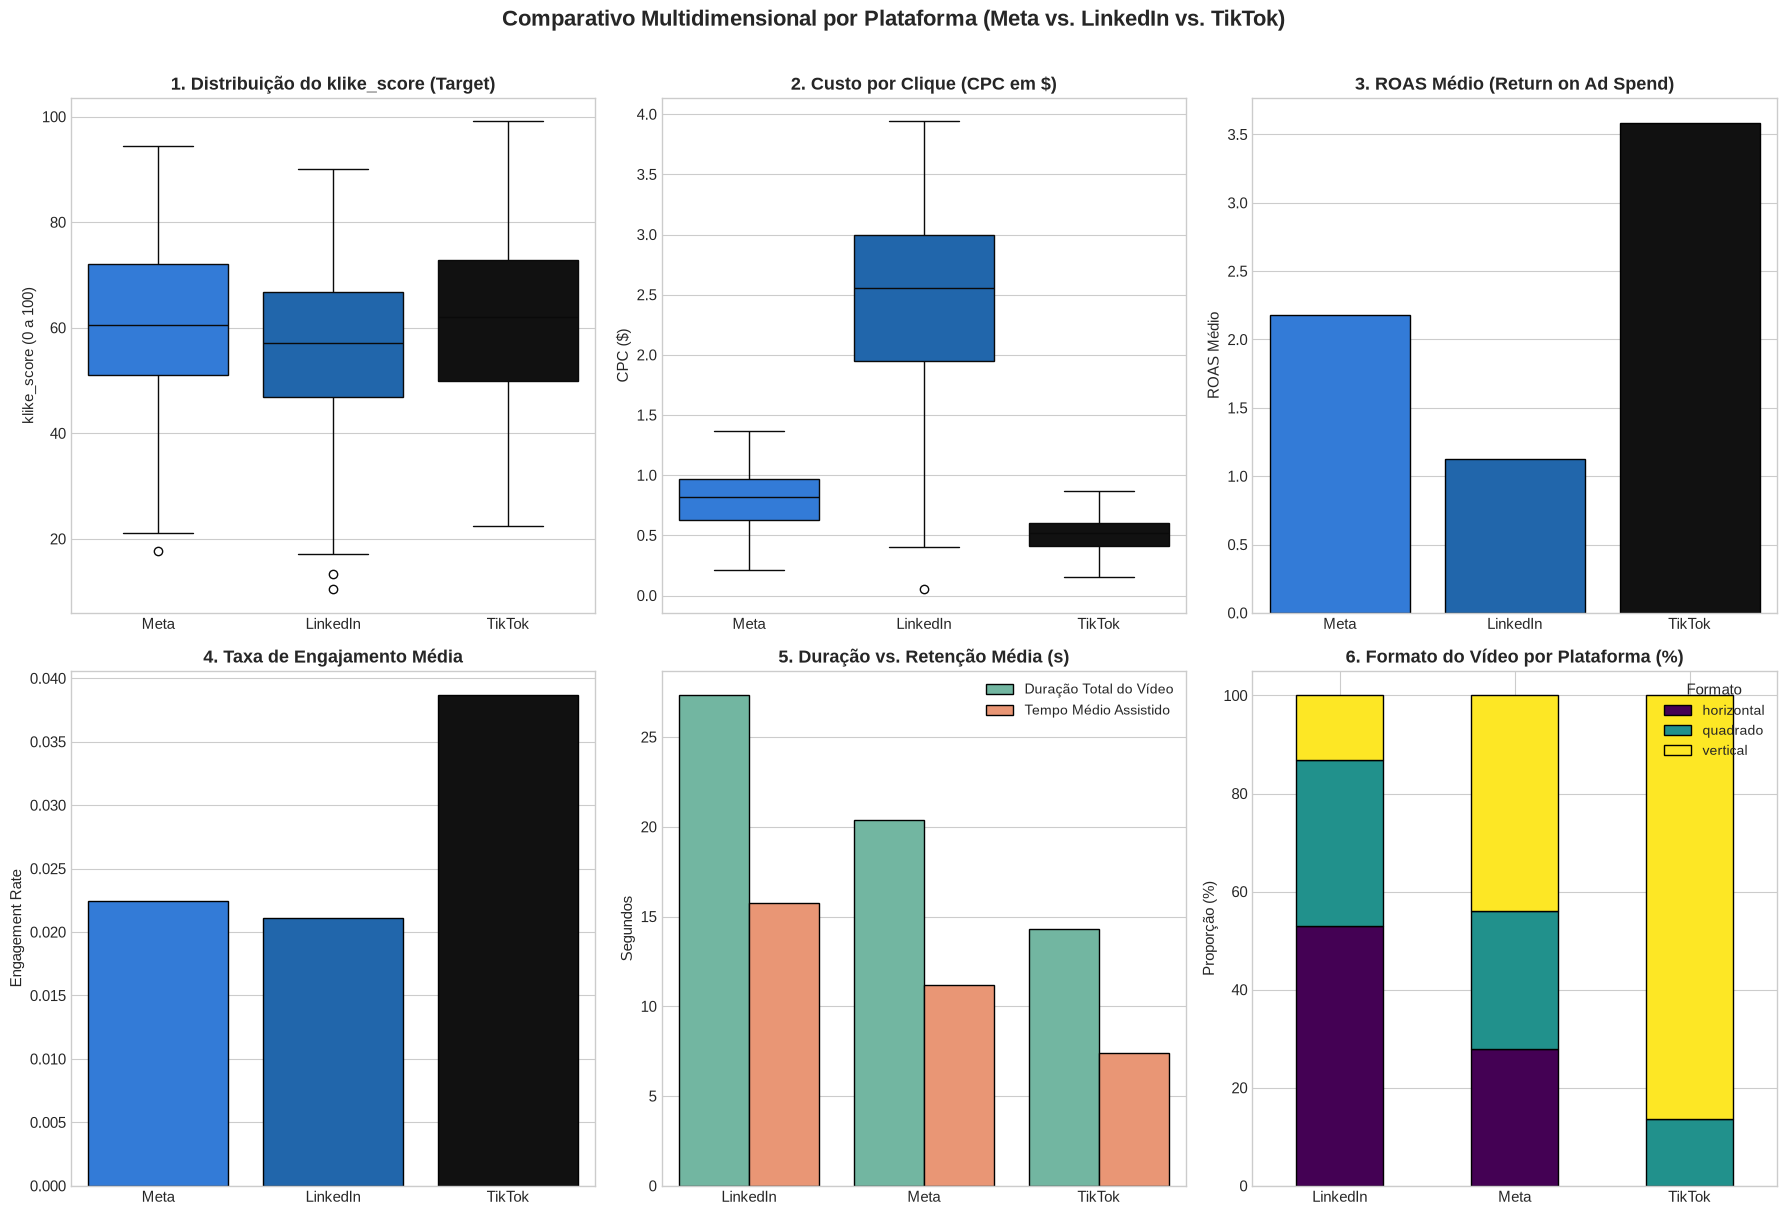

In [129]:
# Grid de 6 gráficos comparativos por plataforma (2 linhas x 3 colunas)
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 12))
cores_plataformas = {'Meta': '#1877F2', 'TikTok': '#111111', 'LinkedIn': '#0A66C2'}

# 1. Distribuição do Target (klike_score)
sns.boxplot(
    data=df, 
    x='platform', 
    y='klike_score', 
    hue='platform', 
    palette=cores_plataformas, 
    legend=False, 
    ax=axes[0, 0]
)
axes[0, 0].set_title('1. Distribuição do klike_score (Target)', fontsize=13, fontweight='bold')
axes[0, 0].set_xlabel('')
axes[0, 0].set_ylabel('klike_score (0 a 100)')

# 2. Custo por Clique (CPC) - removendo os 3 outliers anômalos da Meta (> $5.00: $20.00, $24.17, $26.05)
df_cpc_plot = df[df['cpc'] <= 5.0]
sns.boxplot(
    data=df_cpc_plot, 
    x='platform', 
    y='cpc', 
    hue='platform', 
    palette=cores_plataformas, 
    legend=False, 
    ax=axes[0, 1]
)
axes[0, 1].set_title('2. Custo por Clique (CPC em $)', fontsize=13, fontweight='bold')
axes[0, 1].set_xlabel('')
axes[0, 1].set_ylabel('CPC ($)')

# 3. Retorno sobre Gasto (ROAS Médio)
sns.barplot(
    data=df, 
    x='platform', 
    y='roas', 
    hue='platform', 
    palette=cores_plataformas, 
    legend=False, 
    ax=axes[0, 2], 
    errorbar=None, 
    edgecolor='black'
)
axes[0, 2].set_title('3. ROAS Médio (Return on Ad Spend)', fontsize=13, fontweight='bold')
axes[0, 2].set_xlabel('')
axes[0, 2].set_ylabel('ROAS Médio')

# 4. Taxa de Engajamento Média
sns.barplot(
    data=df, 
    x='platform', 
    y='engagement_rate', 
    hue='platform', 
    palette=cores_plataformas, 
    legend=False, 
    ax=axes[1, 0], 
    errorbar=None, 
    edgecolor='black'
)
axes[1, 0].set_title('4. Taxa de Engajamento Média', fontsize=13, fontweight='bold')
axes[1, 0].set_xlabel('')
axes[1, 0].set_ylabel('Engagement Rate')

# 5. Duração do Vídeo vs Tempo Médio Assistido
df_tempo = df.groupby('platform')[['video_duration_s', 'avg_watch_time_s']].mean().reset_index()
df_tempo_melt = pd.melt(df_tempo, id_vars='platform', var_name='Métrica', value_name='Segundos')
df_tempo_melt['Métrica'] = df_tempo_melt['Métrica'].map({
    'video_duration_s': 'Duração Total do Vídeo',
    'avg_watch_time_s': 'Tempo Médio Assistido'
})
sns.barplot(
    data=df_tempo_melt, 
    x='platform', 
    y='Segundos', 
    hue='Métrica', 
    ax=axes[1, 1], 
    palette='Set2', 
    edgecolor='black'
)
axes[1, 1].set_title('5. Duração vs. Retenção Média (s)', fontsize=13, fontweight='bold')
axes[1, 1].set_xlabel('')
axes[1, 1].set_ylabel('Segundos')
axes[1, 1].legend(title='', fontsize=10)

# 6. Proporção de Formatos de Vídeo (%) por Plataforma
df_formatos = pd.crosstab(df['platform'], df['format'], normalize='index') * 100
df_formatos.plot(kind='bar', stacked=True, ax=axes[1, 2], colormap='viridis', edgecolor='black')
axes[1, 2].set_title('6. Formato do Vídeo por Plataforma (%)', fontsize=13, fontweight='bold')
axes[1, 2].set_xlabel('')
axes[1, 2].set_ylabel('Proporção (%)')
axes[1, 2].legend(title='Formato', fontsize=10)
axes[1, 2].tick_params(axis='x', rotation=0)

plt.suptitle('Comparativo Multidimensional por Plataforma (Meta vs. LinkedIn vs. TikTok)', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


### 7.2 Diagnóstico dos Padrões Identificados entre as Plataformas

A análise visual e estatística revela disparidades marcantes entre as três redes:

1. **Diferenças no Custo por Clique (`cpc`) e Orçamentos**:
   - **LinkedIn**: Apresenta CPC expressivamente mais elevado (mediana de **$2.56** e média de **$2.45**), cerca de **5x maior que o TikTok**. Isso reflete o público B2B altamente qualificado e leilões mais caros. Os investimentos médios (`spend`) também são os maiores do dataset (~$11.000).
   - **TikTok**: Menor CPC de todos (mediana de **$0.52** e média de **$0.51**), permitindo tráfego em escala com menor custo financeiro.
   - **Meta**: Apresenta mediana de **$0.82**, situando-se de forma consistente entre o TikTok e o LinkedIn. Três campanhas atípicas registraram CPCs anômalos de **$20.00, $24.17 e $26.05** (removidos da visualização do boxplot para descompactar o eixo $Y$ e evidenciar o padrão real da maioria dos criativos).

2. **Eficiência Financeira (`roas`) e Target (`klike_score`)**:
   - **TikTok**: Lidera em **ROAS médio (3.59)** e atinge a maior média de `klike_score` (**61.65**). A combinação de baixo CPC e alto engajamento potencializa o retorno sobre investimento.
   - **Meta**: ROAS intermediário saudável (**2.18**) e `klike_score` médio de **60.40**.
   - **LinkedIn**: Menor ROAS médio (**1.13**) e menor `klike_score` médio (**56.31**), em decorrência do custo de mídia muito elevado.

3. **Dinâmica de Vídeo (Duração vs. Retenção)**:
   - **TikTok**: Criativos ultracurtos e dinâmicos (duração média de **14.3s** e retenção de **7.4s**). O consumo é rápido e exige impacto imediato nos primeiros segundos (`has_hook`).
   - **LinkedIn**: Criativos significativamente mais longos (duração média de **27.3s** e retenção média de **15.8s**), refletindo conteúdos mais explicativos e institucionais.
   - **Meta**: Comportamento intermediário (duração média de **20.4s** e retenção de **11.2s**).

4. **Aderência a Formatos de Tela (`format`)**:
   - **TikTok**: **100% dos vídeos são verticais (86.4%) ou quadrados (13.6%)**. Não existe nenhum vídeo horizontal no dataset para o TikTok.
   - **LinkedIn**: Predominância de vídeos **horizontais (53.0%)** e quadrados (33.7%), com baixa adesão a verticais (13.3%).
   - **Meta**: Distribuição equilibrada entre vertical (44.0%), quadrado (28.2%) e horizontal (27.8%).

5. **Implicações Diretas para a Modelagem Preditiva**:
   - A variável `platform` é **indispensável** no pipeline preditivo. Como as métricas operam em patamares completamente distintos por plataforma, o modelo precisa diferenciar o peso do CPC e da duração dependendo da rede;
   - Para modelos lineares, a normalização global do `cpc` sem considerar a plataforma pode prejudicar a calibração (um CPC de $1.50$ é barato no LinkedIn, mas caro no TikTok). Modelos baseados em árvores (como LightGBM e XGBoost) ou engenharia de features com agrupamento por plataforma se beneficiarão amplamente dessa diferenciação.


---
## 8. Visualizações Estratégicas para o Time de Marketing

Enquanto engenheiros de dados e cientistas avaliam métricas estatísticas e funções de perda, um time de **Growth, Mídia e Criação** precisa de respostas diretas para três perguntas fundamentais de negócio:
1. **Como criar um criativo de alta performance?** (Anatomia do Criativo);
2. **Onde e como alocar o orçamento com maior retorno financeiro?** (Eficiência de Mídia);
3. **Qual é o checklist prático indispensável antes de subir qualquer anúncio?** (Priorização de Elementos Criativos).

Abaixo estão três visualizações desenhadas especificamente para apresentar esses direcionamentos de forma clara e orientada a ações.

### 8.1 Visualização 1: Impacto do rosto e do gancho no CTR e no klike_score

**Pergunta de Negócio**: *Qual é a diferença prática entre produzir um anúncio padrão vs. investir em um gancho nos primeiros 3 segundos e colocar um apresentador/pessoa real em tela?*

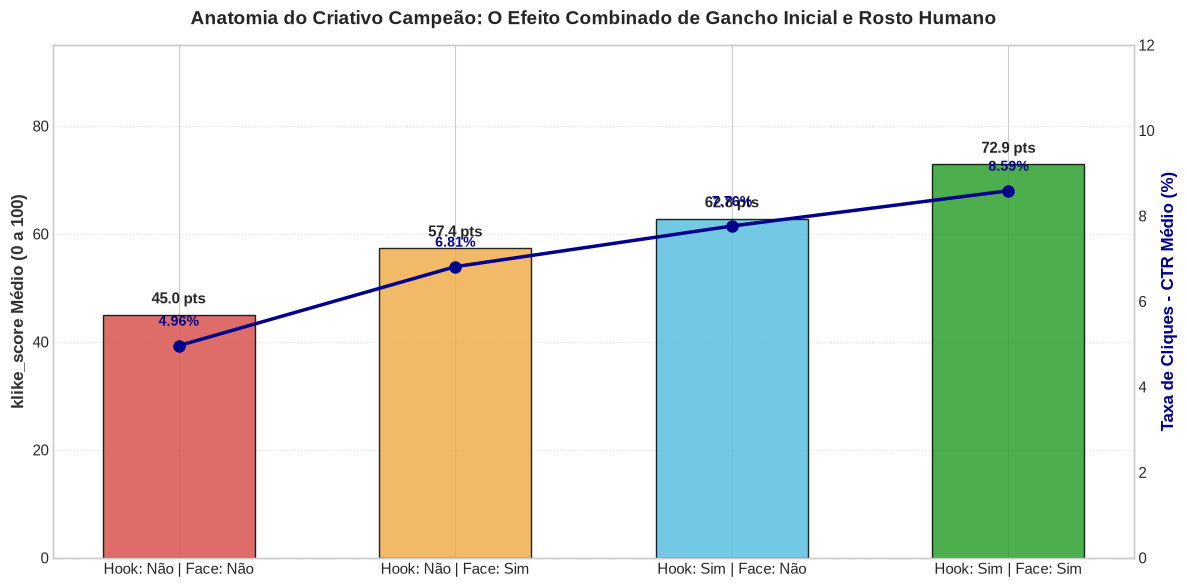

In [130]:
# Construção da Matriz Combinatória de Criativos
df_criativo = df.copy()
df_criativo['Combo Criativo'] = df_criativo.apply(
    lambda r: f"Hook: {'Sim' if r['has_hook'] else 'Não'} | Face: {'Sim' if r['has_face'] else 'Não'}", axis=1
)

ordem_combos = [
    'Hook: Não | Face: Não',
    'Hook: Não | Face: Sim',
    'Hook: Sim | Face: Não',
    'Hook: Sim | Face: Sim'
]

fig, ax1 = plt.subplots(figsize=(12, 6))

resumo_combo = df_criativo.groupby('Combo Criativo').agg({
    'klike_score': 'mean',
    'ctr': lambda x: x.mean() * 100
}).loc[ordem_combos]

cores = ['#d9534f', '#f0ad4e', '#5bc0de', '#2ca02c']
bars = ax1.bar(resumo_combo.index, resumo_combo['klike_score'], color=cores, width=0.55, edgecolor='black', alpha=0.85)

ax1.set_ylabel('klike_score Médio (0 a 100)', fontsize=12, fontweight='bold', color='#333333')
ax1.set_ylim(0, 95)
ax1.grid(axis='y', linestyle=':', alpha=0.6)

# Eixo secundário para a Taxa de Cliques (CTR Médio)
ax2 = ax1.twinx()
ax2.plot(resumo_combo.index, resumo_combo['ctr'], color='darkblue', marker='o', linewidth=2.5, markersize=8, label='CTR Médio (%)')
ax2.set_ylabel('Taxa de Cliques - CTR Médio (%)', fontsize=12, fontweight='bold', color='darkblue')
ax2.set_ylim(0, 12)
ax2.grid(False)

# Anotações em cada barra
for bar in bars:
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, h + 1.5, f'{h:.1f} pts', ha='center', va='bottom', fontsize=11, fontweight='bold')

for i, txt in enumerate(resumo_combo['ctr']):
    ax2.text(i, txt + 0.4, f'{txt:.2f}%', ha='center', va='bottom', fontsize=10, fontweight='bold', color='darkblue')

plt.title('Anatomia do Criativo Campeão: O Efeito Combinado de Gancho Inicial e Rosto Humano', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

**Insight para Criação e Vídeo**:
- Anúncios sem gancho e sem rosto têm score médio de apenas **45.0** e CTR de **4.96%**;
- Ao incluir tanto o gancho inicial quanto rosto humano em destaque, o score salta para **72.9 pontos (+62% de aumento)** e o CTR sobe para **8.59% (quase o dobro de tráfego pelo mesmo investimento)**;
- **Regra de Ouro**: A criação deve priorizar nos primeiros 3 segundos um gancho forte conduzido por uma pessoa real.

### 8.2 Visualização 2: Onde o Dinheiro é Mais Aproveitado (Eficiência de Capital por Canal e Segmento)

**Pergunta de Negócio**: *Para cada $1.00 investido em anúncios, quanto retorna de receita para o caixa da empresa? Em quais canais e verticais o orçamento rende mais, e onde ele dá prejuízo?*


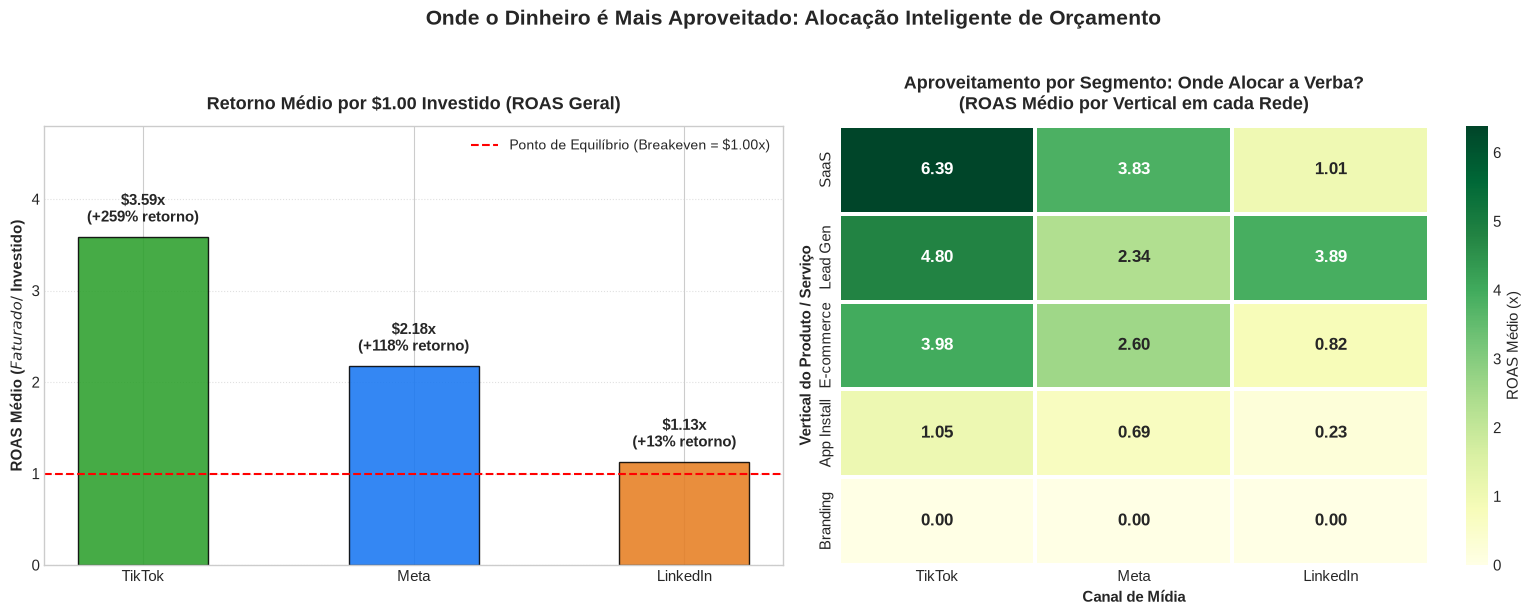

In [131]:
# Painel de Eficiência de Investimento: Visão Global (Esquerda) e Visão por Segmento (Direita)
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

# 1. Gráfico da Esquerda: Retorno Médio por Plataforma (Para cada $1 investido, quanto volta?)
cores_plataformas = {'TikTok': '#2ca02c', 'Meta': '#1877F2', 'LinkedIn': '#e67e22'}
roas_plataforma = df.groupby('platform')['roas'].mean().loc[['TikTok', 'Meta', 'LinkedIn']]

bars = axes[0].bar(
    roas_plataforma.index, 
    roas_plataforma.values, 
    color=[cores_plataformas[p] for p in roas_plataforma.index], 
    edgecolor='black', 
    width=0.48,
    alpha=0.88
)

axes[0].axhline(1.0, color='red', linestyle='--', linewidth=1.5, label='Ponto de Equilíbrio (Breakeven = $1.00x)')
axes[0].set_title('Retorno Médio por $1.00 Investido (ROAS Geral)', fontsize=13, fontweight='bold', pad=12)
axes[0].set_ylabel('ROAS Médio ($ Faturado / $ Investido)', fontsize=11, fontweight='bold')
axes[0].set_ylim(0, 4.8)
axes[0].legend(loc='upper right', fontsize=10)
axes[0].grid(axis='y', linestyle=':', alpha=0.6)

for bar in bars:
    h = bar.get_height()
    lucro = ((h - 1) * 100) if h >= 1 else -((1 - h) * 100)
    texto_lucro = f'+{lucro:.0f}% retorno' if h >= 1 else f'{lucro:.0f}% retorno'
    axes[0].text(
        bar.get_x() + bar.get_width()/2, 
        h + 0.12, 
        f'${h:.2f}x\n({texto_lucro})', 
        ha='center', 
        va='bottom', 
        fontsize=11, 
        fontweight='bold'
    )

# 2. Gráfico da Direita: Matriz de Aproveitamento de Verba (Plataforma vs. Segmento)
pivot_roas = df.pivot_table(index='category', columns='platform', values='roas', aggfunc='mean')[['TikTok', 'Meta', 'LinkedIn']]
ordem_cats = ['SaaS', 'Lead Gen', 'E-commerce', 'App Install', 'Branding']
pivot_roas = pivot_roas.loc[ordem_cats]

sns.heatmap(
    pivot_roas, 
    annot=True, 
    fmt='.2f', 
    cmap='YlGn', 
    linewidths=1.5, 
    linecolor='white',
    cbar_kws={'label': 'ROAS Médio (x)'},
    annot_kws={'fontsize': 12, 'fontweight': 'bold'},
    ax=axes[1]
)
axes[1].set_title('Aproveitamento por Segmento: Onde Alocar a Verba?\n(ROAS Médio por Vertical em cada Rede)', fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel('Canal de Mídia', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Vertical do Produto / Serviço', fontsize=11, fontweight='bold')

plt.suptitle('Onde o Dinheiro é Mais Aproveitado: Alocação Inteligente de Orçamento', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


**Insights para alocação dos investimentos**:

1. **O Campeão Geral de Eficiência de Capital: TikTok**
   - Para cada **$1.00 investido**, o TikTok retorna em média **$3.59 de receita (+259% de retorno)**. O leilão barato aliado ao alto consumo de vídeo curto faz com que o dinheiro renda muito mais do que nas redes tradicionais.
   
2. **Guia de Alocação por Segmento de Produto**:
   - **SaaS (Softwares & Assinaturas)**: O **TikTok lidera com folga (ROAS de 6.39x)**, seguido pela **Meta (3.83x)**. O **LinkedIn quase empata no custo (1.01x)** — ou seja, colocar verba de SaaS no LinkedIn entrega retorno 6x menor do que no TikTok!
   - **E-commerce**: Priorizar **TikTok (3.98x)** e **Meta (2.60x)**. **Evitar o LinkedIn (0.82x)**, pois opera em prejuízo direto (cada dólar investido vira apenas 82 centavos).
   - **Lead Gen (Geração de Contatos B2B/Comerciais)**: Aqui o **TikTok (4.80x)** e o **LinkedIn (3.89x)** são altamente recomendados. No LinkedIn, o público profissional qualificado compensa o CPC caro para gerar leads de alto valor.
   - **App Install**: O ROAS direto é baixo em todas as redes (TikTok: 1.05x, Meta: 0.69x, LinkedIn: 0.23x), pois a conversão final costuma ocorrer via monetização in-app no longo prazo.
   - **Branding**: Campanhas de topo de funil puro não registram faturamento direto imediato (ROAS 0.00x), devendo ser mensuradas por alcance e CPM.


### 8.3 Visualização 3: O Impacto Direto dos 4 Elementos Criativos no klike_score

**Pergunta de Negócio**: *Qual é o ganho médio garantido em pontuação que cada elemento individual agrega ao anúncio?*

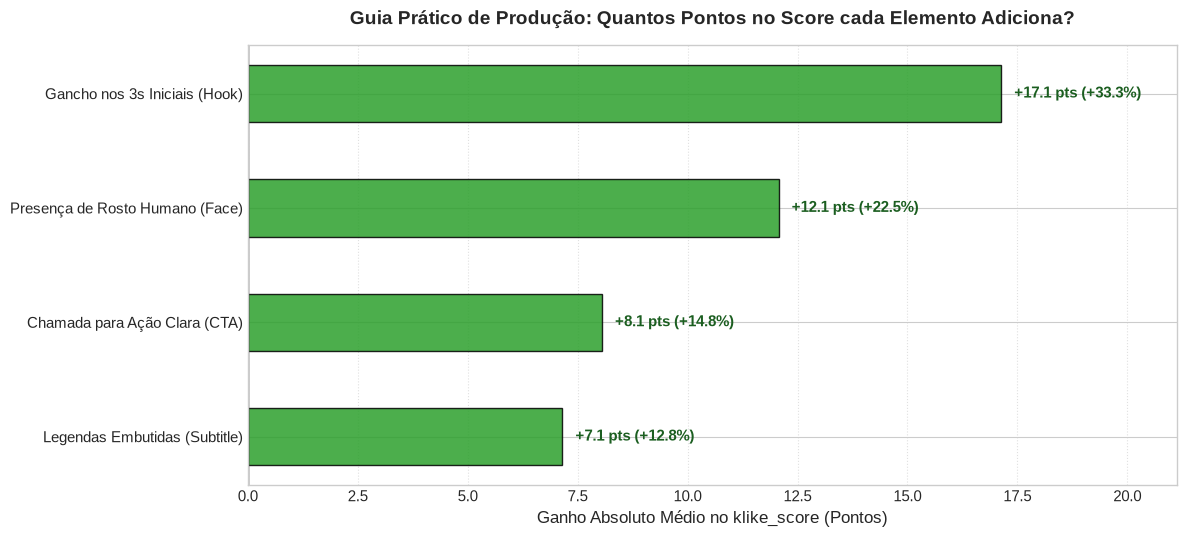

In [132]:
# Cálculo do Lift (Ganho Absoluto e Percentual) para cada elemento do criativo
elementos = [
    ('has_hook', 'Gancho nos 3s Iniciais (Hook)'),
    ('has_face', 'Presença de Rosto Humano (Face)'),
    ('has_cta', 'Chamada para Ação Clara (CTA)'),
    ('has_subtitle', 'Legendas Embutidas (Subtitle)')
]

metricas_lift = []
for col, nome in elementos:
    media_com = df[df[col] == True]['klike_score'].mean()
    media_sem = df[df[col] == False]['klike_score'].mean()
    lift_pts = media_com - media_sem
    lift_pct = (lift_pts / media_sem) * 100
    metricas_lift.append({
        'Elemento': nome,
        'Com o Recurso': media_com,
        'Sem o Recurso': media_sem,
        'Ganho (Lift Pontos)': lift_pts,
        'Ganho (Lift %)': lift_pct
    })

df_lift = pd.DataFrame(metricas_lift).sort_values(by='Ganho (Lift Pontos)', ascending=True)

plt.figure(figsize=(12, 5.5))
bars = plt.barh(df_lift['Elemento'], df_lift['Ganho (Lift Pontos)'], color='#2ca02c', edgecolor='black', alpha=0.85, height=0.5)
plt.axvline(0, color='black', linewidth=1)
plt.title('Guia Prático de Produção: Quantos Pontos no Score cada Elemento Adiciona?', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Ganho Absoluto Médio no klike_score (Pontos)', fontsize=12)
plt.grid(axis='x', linestyle=':', alpha=0.6)

for bar, pct in zip(bars, df_lift['Ganho (Lift %)']):
    w = bar.get_width()
    plt.text(w + 0.3, bar.get_y() + bar.get_height()/2, f'+{w:.1f} pts (+{pct:.1f}%)', 
             va='center', ha='left', fontsize=11, fontweight='bold', color='#1b5e20')

plt.xlim(0, max(df_lift['Ganho (Lift Pontos)']) + 4)
plt.tight_layout()
plt.show()

**Checklist de Aprovação de Criativos (Playbook para a Equipe)**:
Antes de autorizar a veiculação de qualquer anúncio, o time de marketing pode utilizar este ranking de impacto:
1. **Gancho Inicial nos primeiros 3s (`has_hook`)**: Adiciona **+17.1 pontos (+33.3%)** ao score — *Item Não Negociável*;
2. **Pessoas/Rosto Real (`has_face`)**: Adiciona **+12.1 pontos (+22.5%)** ao score — *Humaniza o criativo e gera conexão*;
3. **Call to Action Clara (`has_cta`)**: Adiciona **+8.1 pontos (+14.8%)** ao score — *Garante direcionamento e conversão no final*;
4. **Legendas Embutidas (`has_subtitle`)**: Adiciona **+7.1 pontos (+12.8%)** ao score — *Recupera usuários que assistem sem fone de ouvido ou no mudo*.